In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
import os

print(os.listdir())

['.ipynb_checkpoints', '1768648785295-Section-3-Basic-Python-AI-Powered.pdf', 'caste certificate.pdf', 'ChromeSetup.exe', 'CV-FRONTEND_DEVELOPER_REACT_DEVELOPER-SRUSHTI_NERKAR.pdf', 'desktop.ini', 'doreamon.jpg', 'EduPlusCampus.pdf', 'ID CARD.pdf', 'KMS_VL_ALL_AIO-master', 'KMS_VL_ALL_AIO-master.zip', 'lead genration resume.jpeg', 'LinkedIn_Profile.pdf', 'Mayuri_Kharote_Resume.pdf', 'Microsoft Office 2019-2021 Pro Plus', 'Microsoft Office 2019-2021 Pro Plus.zip', 'mongodb-compass-1.52.0-win32-x64.exe', 'mongodb-windows-x86_64-9.0.2-signed.msi', 'mysql-9.7.1-winx64 (1).msi', 'mysql-9.7.1-winx64.msi', 'mysql-installer-web-community-8.0.45.0.msi', 'node-v20.12.2-x64.msi', 'OASIS INFOBYTE — Task List.pdf', 'OIBSIP_Task1_Retail_Sales_EDA.ipynb', 'Perceptron Hackathon by optiver.pdf', 'photo (1).jpeg', 'photo (1).pdf', 'photo.jpeg', 'photo.pdf', 'PORNIMA NERKAR RESUME1 (1).docx', 'PORNIMA NERKAR WEB DEVELOPEMENT RESUME (1).pdf', 'Pornima Onkar Nerkar_Offer_Letter.pdf', 'Pornima_Nerkar_Data_A

In [3]:
# Load the retail sales dataset
df = pd.read_csv('retail_sales_dataset.csv')

# Display success message
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [6]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [7]:
# Descriptive statistics

print("MEAN:")
print(df.mean(numeric_only=True))

print("\nMEDIAN:")
print(df.median(numeric_only=True))

print("\nMODE:")
print(df.mode().iloc[0])

print("\nSTANDARD DEVIATION:")
print(df.std(numeric_only=True))

MEAN:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE:
Transaction ID               1
Date                2023-05-16
Customer ID            CUST001
Gender                  Female
Age                       43.0
Product Category      Clothing
Quantity                   4.0
Price per Unit            50.0
Total Amount              50.0
Name: 0, dtype: object

STANDARD DEVIATION:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [8]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [9]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Extract month and year
df['Month'] = df['Date'].dt.to_period('M')

print("Date conversion successful!")

Date conversion successful!


In [10]:
# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

print(monthly_sales)

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


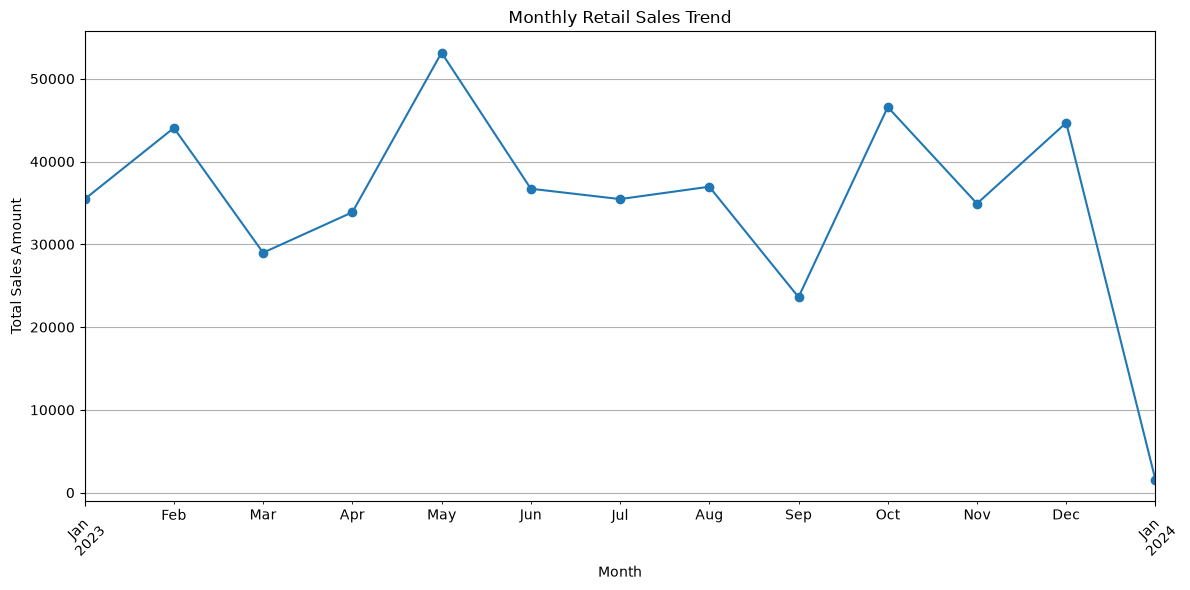

In [11]:
plt.figure(figsize=(12, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

### Monthly Sales Trend Analysis

The monthly sales trend analysis helps identify changes in retail sales over time. The line chart shows monthly revenue fluctuations and helps identify months with relatively high and low sales.

These observations can help businesses understand sales patterns and plan inventory and marketing activities accordingly.

### Observation – Monthly Sales Trend

- May 2023 recorded the highest sales during the analysed period.
- September 2023 showed a significant decline in sales.
- October 2023 experienced a strong recovery.
- Sales fluctuated throughout the year rather than following a consistent upward trend.
- January 2024 recorded very low sales, which may be due to incomplete monthly data.

**Conclusion:** The business should investigate the reasons behind monthly sales fluctuations and plan promotional campaigns during low-sales periods.

In [12]:
# Extract quarterly sales
df['Quarter'] = df['Date'].dt.to_period('Q')

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print(quarterly_sales)

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


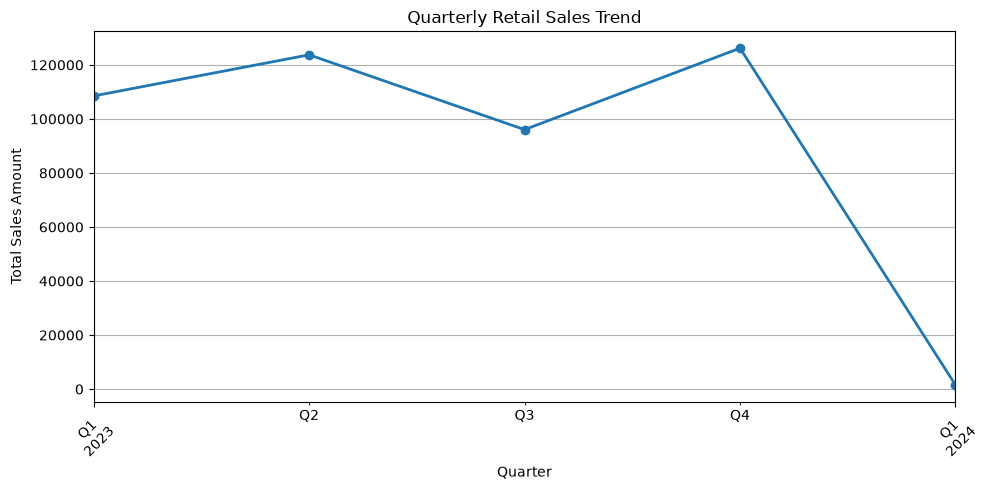

In [13]:
plt.figure(figsize=(10, 5))

quarterly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Quarterly Retail Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales Amount')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Quarterly Sales Trend Analysis

- Q2 2023 showed an improvement in sales compared to Q1.
- Q3 2023 experienced a decline in total sales.
- Q4 2023 recorded the highest quarterly sales.
- Q1 2024 contains only January data, so it should not be compared directly with complete quarters.

**Conclusion:** The fourth quarter performed strongly. The business should investigate successful strategies used during this period and consider applying them in other quarters.

In [14]:
# Create customer age groups

bins = [0, 20, 30, 40, 50, 60, 100]

labels = [
    'Below 20',
    '20-30',
    '31-40',
    '41-50',
    '51-60',
    'Above 60'
]

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

# Count customers in each age group
age_counts = df['Age Group'].value_counts().sort_index()

print(age_counts)

Age Group
Below 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64


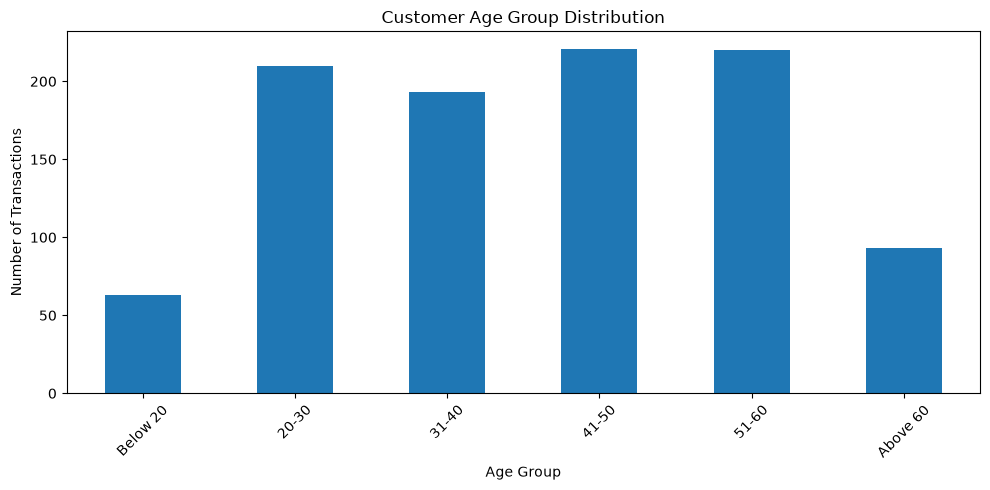

In [15]:
plt.figure(figsize=(10, 5))

age_counts.plot(kind='bar')

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Count gender distribution

gender_counts = df['Gender'].value_counts()

print(gender_counts)

Gender
Female    510
Male      490
Name: count, dtype: int64


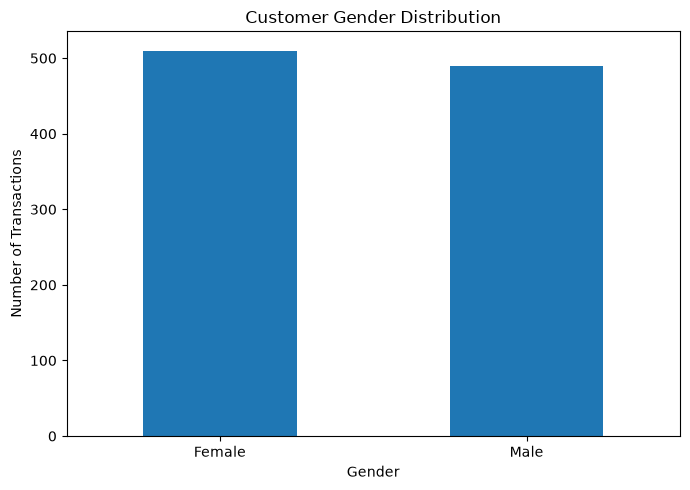

In [17]:
plt.figure(figsize=(7, 5))

gender_counts.plot(
    kind='bar',
    rot=0
)

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

### Customer Gender Distribution Analysis

The gender distribution analysis shows that female customers contribute slightly more transactions than male customers.

The distribution is relatively balanced, indicating that both genders actively participate in retail purchases.

**Business Insight:** The business should maintain marketing strategies that appeal to both male and female customers while exploring product preferences across genders.

In [18]:
# Calculate quantity sold by product category

category_sales = df.groupby(
    'Product Category'
)['Quantity'].sum().sort_values(ascending=False)

print(category_sales)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


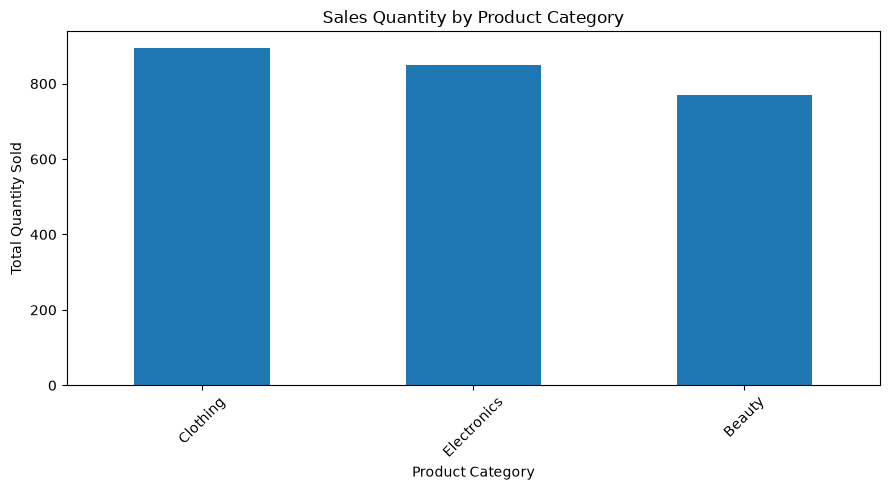

In [19]:
plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title('Sales Quantity by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
category_revenue = df.groupby(
    'Product Category'
)['Total Amount'].sum().sort_values(ascending=False)

print(category_revenue)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


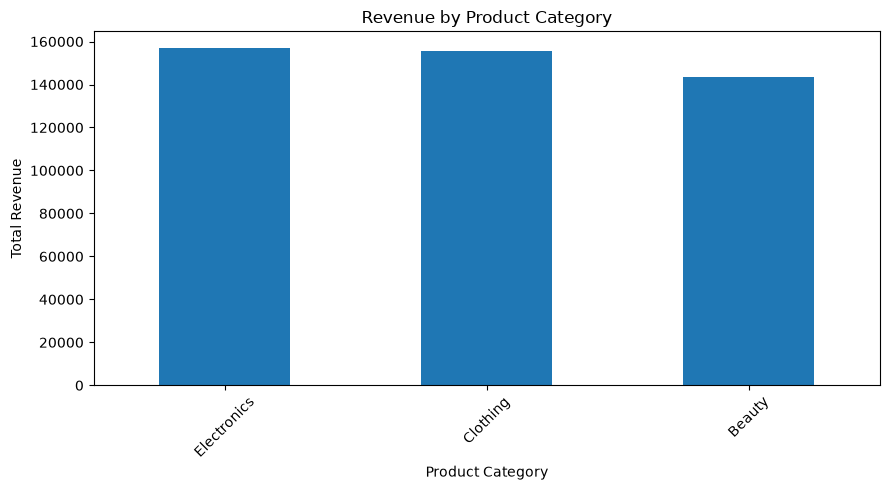

In [21]:
plt.figure(figsize=(9, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Revenue by Product Category Analysis

The analysis shows that Electronics generated the highest revenue, followed closely by Clothing. Beauty generated comparatively lower revenue.

**Business Insight:** The business should maintain sufficient inventory for Electronics and Clothing while exploring promotional offers and marketing strategies to improve Beauty category sales.

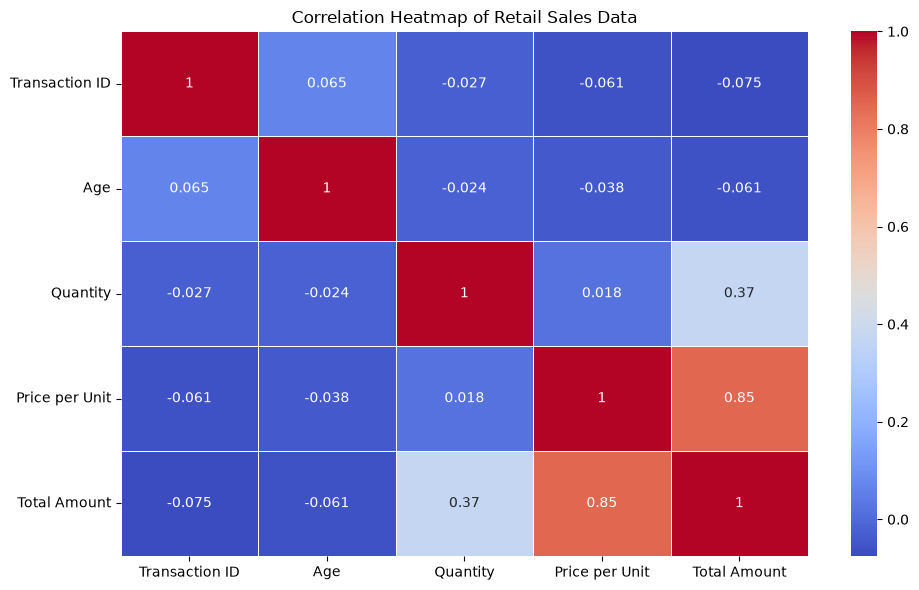

In [22]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.show()

### Correlation Heatmap Analysis

The correlation heatmap illustrates the relationships between numerical variables in the retail sales dataset.

- Price per Unit and Total Amount have a strong positive correlation of 0.85.
- Quantity and Total Amount have a moderate positive correlation of 0.37.
- Age and Total Amount have a very weak negative correlation of -0.061.
- Age and Quantity have almost no correlation.

**Conclusion:** Product pricing and purchase quantity are more closely associated with transaction revenue than customer age.

**Business Insight:** The business should focus on product pricing strategies, product bundles and quantity-based promotions to improve revenue.

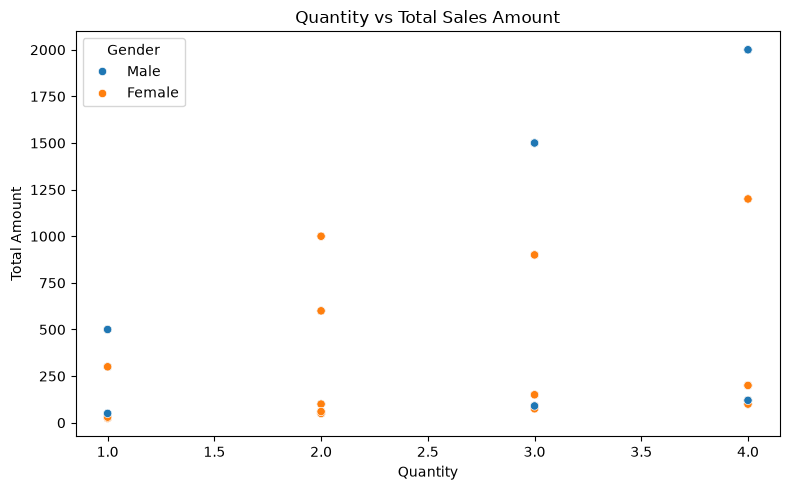

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total Amount',
    hue='Gender'
)

plt.title('Quantity vs Total Sales Amount')
plt.xlabel('Quantity')
plt.ylabel('Total Amount')

plt.tight_layout()
plt.show()

### Quantity vs Total Sales Amount Analysis

The scatter plot illustrates the relationship between the quantity of products purchased and the total transaction amount.

The analysis shows that transaction amounts vary across different purchase quantities. Higher quantities can result in higher transaction values, although the price per unit also influences the total amount.

Both male and female customers show variations in their spending patterns.

**Business Insight:** The business can introduce quantity-based discounts and product bundles to encourage customers to purchase more items.

# Final Business Recommendations

Based on the Exploratory Data Analysis of the Retail Sales Dataset, the following recommendations are proposed:

**1. Improve Low-Sales Periods**

Analyse months with lower sales and introduce seasonal discounts, promotional campaigns and special offers to improve revenue.

**2. Focus on High-Revenue Categories**

Electronics and Clothing generated higher revenue than Beauty. Maintain sufficient inventory and promote these categories to sustain sales performance.

**3. Introduce Product Bundles**

Offer discounts on bulk purchases and product combinations to encourage customers to purchase more items per transaction.

**4. Improve Beauty Category Performance**

Introduce targeted promotional campaigns and attractive offers to increase customer interest in Beauty products.

**5. Monitor Customer Purchasing Behaviour**

Continue analysing customer demographics and transaction patterns to develop effective marketing strategies.

# Conclusion

The Exploratory Data Analysis of the Retail Sales Dataset provided useful insights into sales trends, customer demographics and product category performance.

The analysis covered 1,000 retail transactions with 9 columns. The dataset contained no missing values.

Monthly and quarterly sales analysis revealed fluctuations in revenue throughout the observed period. Customer demographic analysis showed a relatively balanced gender distribution. Product category analysis identified Electronics and Clothing as the leading revenue contributors.

The correlation analysis showed a strong positive relationship between Price per Unit and Total Amount.

Overall, this project demonstrates how Python, Pandas, Matplotlib and Seaborn can be used to analyse retail sales data and generate actionable business insights.